# Early prediction on the recorded PowerFactory events

How soon after fault inception can stability be predicted? 500 recorded events per system, feature models on trajectory features and sequence models on the resampled trajectories, all on the same 5 stratified folds.

The event files are not bundled; set `TRANPY_EVENTS_DIR` to the folder with `new_england_events.npz` and `ieee_9bus_events.npz` (or a folder of PowerFactory CSVs per system).

In [1]:
import logging, os, warnings
import numpy as np
import pandas as pd
import tranpy
from tranpy.early_prediction import find_knee_point, run_early_prediction
from tranpy.plotting import plot_early_prediction
from tranpy_core.models import make_pipeline
from pathlib import Path
import matplotlib.pyplot as plt
from tranpy_core.plotting import publication_style, save_figure

FIGURES = Path("outputs")
plt.rcParams["figure.dpi"] = 150

warnings.filterwarnings("ignore", category=FutureWarning)
EVENTS = Path(os.environ.get("TRANPY_EVENTS_DIR", Path.home() / "tranpy-data" / "events"))
WINDOWS = (0.05, 0.1, 0.2, 0.4, 0.8)

## Models

In [2]:
feature_models = {
    "logistic regression": make_pipeline("logistic_regression", max_iter=5000),
    "random forest": make_pipeline("random_forest", seed=0),
    "xgboost": make_pipeline("xgboost", seed=0),
    "lightgbm": make_pipeline("lightgbm", seed=0),
}
network = dict(epochs=60, early_stopping_patience=8, seed=0)
sequence_models = {
    "dense network": make_pipeline("dense_network", hidden_units=(64, 32), **network),
    "lstm": make_pipeline("lstm_network", lstm_units=(32,), dense_units=16, **network),
    "tcn": make_pipeline("tcn_network", n_filters=32, dilation_rates=(1, 2, 4), dense_units=16, **network),
    "transformer": make_pipeline("transformer_network", d_model=32, n_heads=4, n_layers=1, ff_dim=64, dense_units=16, **network),
}

## Run (windows from fault inception)

Results are cached in `outputs/`; delete the CSV to recompute.

In [3]:
results = {}
for system in ("ieee_9bus", "new_england"):
    cache = FIGURES / f"07_{system}_fault_start.csv"
    if cache.exists():
        results[system] = pd.read_csv(cache)
        continue
    events = tranpy.load_events(system, source=EVENTS / f"{system}_events.npz")
    results[system] = run_early_prediction(events, feature_models, sequence_models=sequence_models,
                                           reference="fault_start", windows_s=WINDOWS, n_splits=5, seed=42)
    cache.parent.mkdir(exist_ok=True)
    results[system].to_csv(cache, index=False)

In [4]:
columns = ["window_s", "model", "input", "accuracy_mean", "accuracy_std", "roc_auc_mean", "f1_mean", "fit_time_s"]
for system, frame in results.items():
    print(system)
    display(frame[columns].round(3))

ieee_9bus


,window_s,model,input,accuracy_mean,accuracy_std,roc_auc_mean,f1_mean,fit_time_s
0,0.05,logistic regression,features,0.954,0.010,0.994,0.950,0.006
1,0.05,random forest,features,0.966,0.015,0.996,0.964,0.104
2,0.05,xgboost,features,0.974,0.010,0.997,0.972,0.076
3,0.05,lightgbm,features,0.978,0.012,0.996,0.976,0.332
4,0.05,dense network,sequence,0.968,0.012,0.998,0.966,3.696
5,0.05,lstm,sequence,0.958,0.022,0.995,0.955,4.295
6,0.05,tcn,sequence,0.970,0.018,0.993,0.968,5.079
7,0.05,transformer,sequence,0.962,0.019,0.994,0.959,5.716
8,0.10,logistic regression,features,0.948,0.013,0.994,0.944,0.006
9,0.10,random forest,features,0.968,0.007,0.997,0.965,0.110


new_england


,window_s,model,input,accuracy_mean,accuracy_std,roc_auc_mean,f1_mean,fit_time_s
0,0.05,logistic regression,features,0.876,0.022,0.929,0.880,0.028
1,0.05,random forest,features,0.980,0.021,0.996,0.980,0.255
2,0.05,xgboost,features,0.984,0.010,0.993,0.984,0.744
3,0.05,lightgbm,features,0.978,0.016,0.994,0.978,0.511
4,0.05,dense network,sequence,0.904,0.039,0.960,0.904,9.160
5,0.05,lstm,sequence,0.858,0.049,0.921,0.851,11.835
6,0.05,tcn,sequence,0.812,0.058,0.889,0.815,18.850
7,0.05,transformer,sequence,0.842,0.053,0.908,0.837,12.766
8,0.10,logistic regression,features,0.884,0.020,0.935,0.885,0.018
9,0.10,random forest,features,0.990,0.011,0.997,0.990,0.383


In [5]:
pd.DataFrame({system: {m: find_knee_point(f, m) for m in f.model.unique()} for system, f in results.items()})

,ieee_9bus,new_england
logistic regression,0.1,0.1
random forest,0.2,0.1
xgboost,0.1,0.2
lightgbm,0.1,0.2
dense network,0.1,0.4
lstm,0.4,0.4
tcn,0.4,0.1
transformer,0.1,0.1


## Accuracy versus observation window

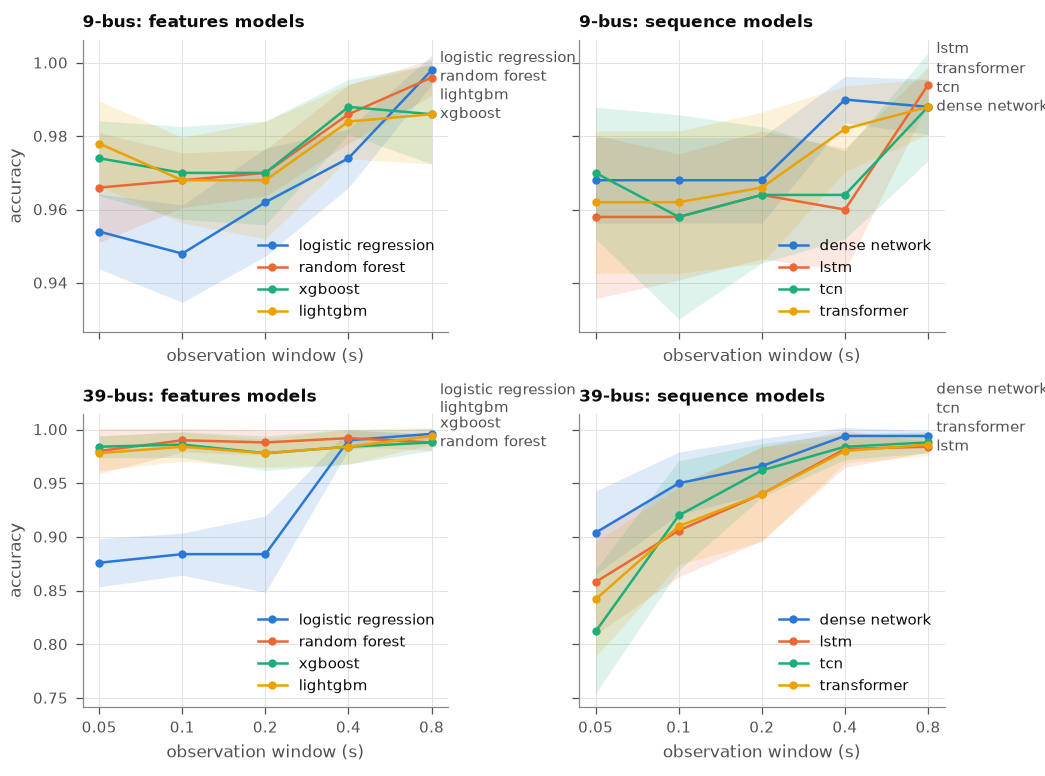

In [6]:
with publication_style():
    fig, axes = plt.subplots(2, 2, figsize=(7.0, 5.2), sharex=True, sharey="row")
    for row, (system, label) in enumerate([("ieee_9bus", "9-bus"), ("new_england", "39-bus")]):
        frame = results[system]
        for col, kind in enumerate(("features", "sequence")):
            plot_early_prediction(frame[frame.input == kind], ax=axes[row, col],
                                  title=f"{label}: {kind} models")
            if col:
                axes[row, col].set_ylabel("")
    fig.tight_layout()
    save_figure(fig, FIGURES / "07_early_prediction_real.pdf")
plt.show()

## How optimistic were clearing-based windows?

Same models and folds, windows measured from the detected fault clearing instead of fault inception. Detected clearing is late for collapsing events, so these windows contain information about the outcome.

In [7]:
fast = {k: feature_models[k] for k in ("random forest", "xgboost")}
comparison = []
for system in ("ieee_9bus", "new_england"):
    events = tranpy.load_events(system, source=EVENTS / f"{system}_events.npz")
    for reference in ("fault_start", "fault_clear"):
        frame = run_early_prediction(events, fast, reference=reference, windows_s=WINDOWS, n_splits=5, seed=42)
        comparison.append(frame.assign(system=system, reference=reference))
comparison = pd.concat(comparison)
comparison.pivot_table(index=["system", "model", "window_s"], columns="reference", values="accuracy_mean").round(3)

reference                           fault_clear  fault_start
system      model         window_s                          
ieee_9bus   random forest 0.05            0.998        0.966
                          0.10            1.000        0.968
                          0.20            1.000        0.970
                          0.40            0.998        0.986
                          0.80            0.998        0.996
            xgboost       0.05            0.990        0.974
                          0.10            0.992        0.970
                          0.20            0.992        0.970
                          0.40            0.996        0.988
                          0.80            0.998        0.986
new_england random forest 0.05            0.990        0.980
                          0.10            0.992        0.990
                          0.20            0.992        0.988
                          0.40            0.994        0.992
                          0.80            0.994        0.988
            xgboost       0.05            0.988        0.984
                          0.10            0.988        0.986
                          0.20            0.988        0.978
                          0.40            0.986        0.984
                          0.80            0.994        0.988